# Tech Challenge — Fase 1
## Sistema inteligente de suporte ao diagnóstico em saúde da mulher

**Aplicação de Machine Learning à classificação de risco de câncer de mama**

---

### Contexto do problema

Uma rede de hospitais especializados no atendimento à mulher precisa de um
sistema de IA que ajude os profissionais de saúde a identificar precocemente
condições de risco. Com um volume crescente de pacientes, acelerar a triagem
e apoiar a decisão médica salva vidas.

Nesta primeira fase, construímos a **base de Machine Learning**: um modelo que
analisa dados de exames e classifica automaticamente o risco de um tumor de
mama ser **maligno** ou **benigno**.

### Base de dados escolhida

**Breast Cancer Wisconsin (Diagnostic)** — 569 pacientes, 30 features
numéricas extraídas de imagens digitalizadas de aspirados por agulha fina
(PAAF) de massas mamárias. Cada feature descreve uma característica dos
núcleos celulares (raio, textura, perímetro, área, concavidade, etc.),
resumida por *média*, *erro-padrão* e *pior valor* ("worst").

É a base sugerida no enunciado, é pública e vem embutida no scikit-learn, o
que torna todo o projeto 100% reprodutível.

### O problema a resolver

> Dado o resultado quantitativo de um exame, **classificar o tumor como
> maligno ou benigno**, priorizando a detecção dos casos malignos.

Trata-se de um problema de **classificação binária supervisionada**.


## 1. Configuração do ambiente

In [1]:
# Permite importar o pacote src/ a partir da pasta notebooks/
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data_loader, eda, modeling, evaluation, explainability
from src.preprocessing import clean_data, missing_report, split_data, build_preprocessor

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
print("Semente global:", config.RANDOM_STATE)
print("Convenção de rótulo:", config.CLASS_NAMES)


Semente global: 42
Convenção de rótulo: {0: 'benigno', 1: 'maligno'}


## 2. Carregamento e primeira inspeção dos dados

Carregamos a base já com o alvo remapeado para a **convenção clínica** do
projeto: `1 = maligno` (classe de interesse) e `0 = benigno`. A justificativa
para isso aparece na seção de métricas.

In [2]:
df = clean_data(data_loader.load_dataframe(save_csv=True))
print(f"Dimensões: {df.shape[0]} pacientes x {df.shape[1]-1} features + 1 alvo")
df.head()


Dimensões: 569 pacientes x 30 features + 1 alvo


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

## 3. Análise exploratória (EDA)

### 3.1 Balanceamento das classes

Verificar o balanceamento é o primeiro passo: bases desbalanceadas exigem
cuidado na escolha da métrica (accuracy pode enganar) e podem se beneficiar de
`class_weight='balanced'` na modelagem.

diagnosis
benigno    357
maligno    212

Proporção de casos malignos: 37.3%


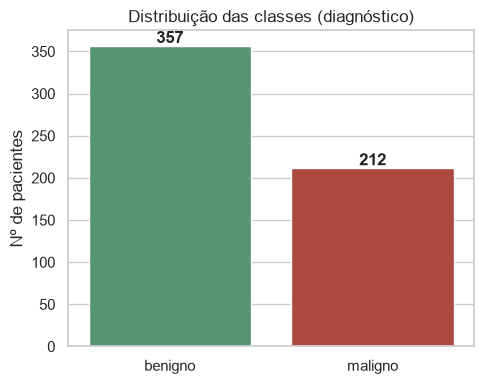

In [4]:
print(eda.class_balance(df).to_string())
prop_maligno = df[config.TARGET_COLUMN].mean()
print(f"\nProporção de casos malignos: {prop_maligno:.1%}")
eda.plot_class_balance(df)
plt.show()


Cerca de **37% dos casos são malignos** — há desbalanceamento moderado.
A classe de maior interesse clínico (maligno) é justamente a minoritária, o
que reforça a necessidade de olhar para **recall**, e não só accuracy.

### 3.2 Estatísticas descritivas

In [5]:
features = data_loader.feature_columns(df)
df[features].describe().T[["mean", "std", "min", "50%", "max"]].round(3)


,mean,std,min,50%,max
mean radius,14.127,3.524,6.981,13.370,28.110
mean texture,19.290,4.301,9.710,18.840,39.280
mean perimeter,91.969,24.299,43.790,86.240,188.500
mean area,654.889,351.914,143.500,551.100,2501.000
mean smoothness,0.096,0.014,0.053,0.096,0.163
mean compactness,0.104,0.053,0.019,0.093,0.345
mean concavity,0.089,0.080,0.000,0.062,0.427
mean concave points,0.049,0.039,0.000,0.034,0.201
mean symmetry,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,0.063,0.007,0.050,0.062,0.097


As features estão em **escalas muito diferentes** (ex.: `mean area` na casa
das centenas vs. `mean smoothness` na casa dos centésimos). Isso torna a
**padronização obrigatória** para modelos sensíveis a escala, como KNN e
Regressão Logística.

### 3.3 Valores ausentes

In [6]:
missing = missing_report(df)
print("Nenhum valor ausente." if missing.empty else missing.to_string())


Nenhum valor ausente.


Não há valores ausentes nesta base. Ainda assim, o pipeline de
pré-processamento inclui imputação pela mediana — assim ele funciona também em
bases mais "sujas" (o mesmo código serve para outros datasets de saúde).

### 3.4 Distribuição das features por classe

Comparamos as distribuições das features mais associadas ao diagnóstico entre
tumores benignos e malignos. Uma boa separação visual indica alto poder
preditivo.

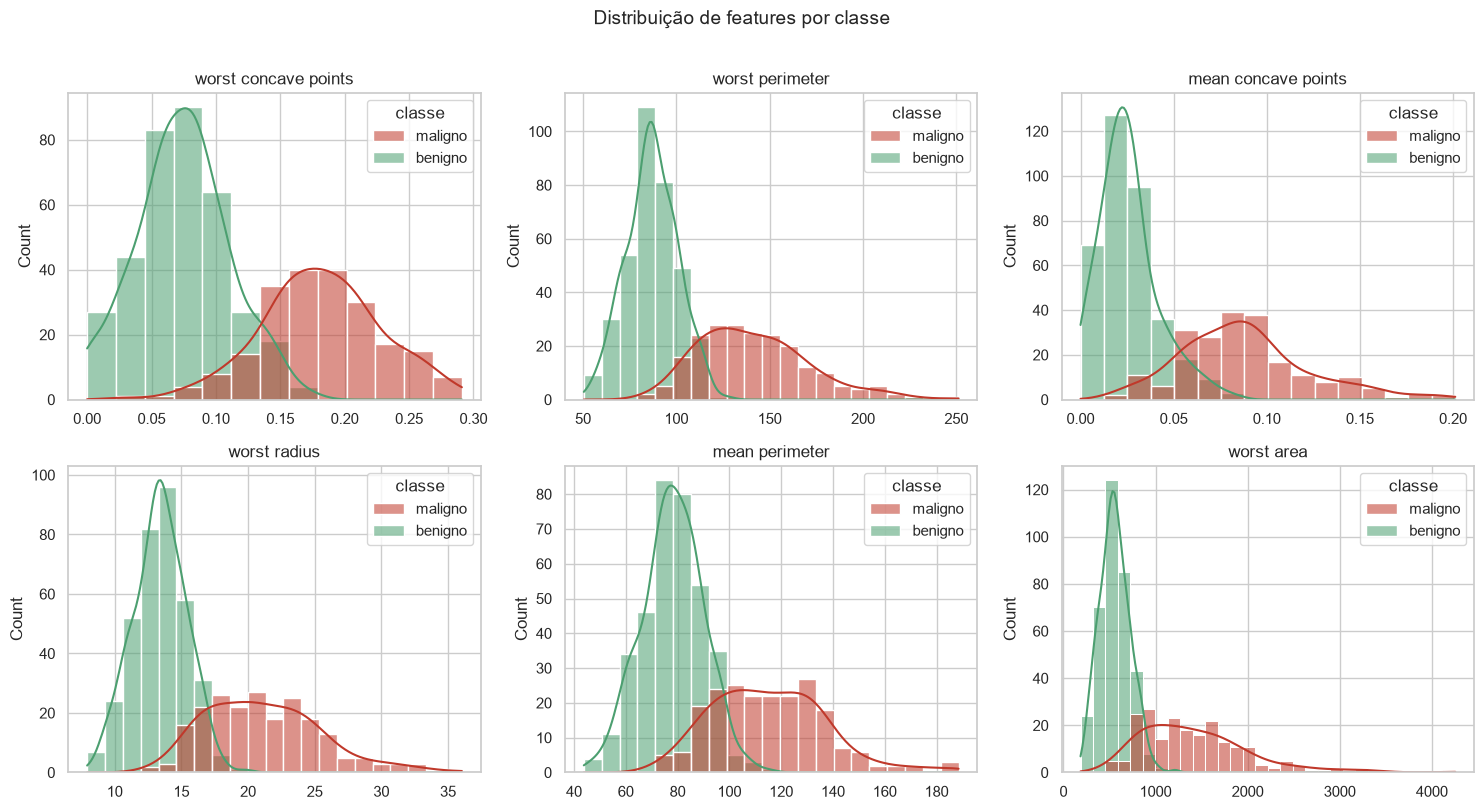

In [7]:
top_corr = eda.top_target_correlations(df, n=10)
eda.plot_feature_distributions(df, features=list(top_corr.index[:6]))
plt.show()


**Padrão claro:** tumores malignos (vermelho) apresentam consistentemente
valores mais altos de raio, perímetro, área e concavidade. As distribuições
mal se sobrepõem em features como `worst concave points` e `worst perimeter`,
o que antecipa que o problema é bastante separável.

### 3.5 Análise de correlação

A matriz de correlação revela dois fenômenos importantes:
1. Quais features mais se associam ao diagnóstico (poder preditivo).
2. Quais features são redundantes entre si (**multicolinearidade**).

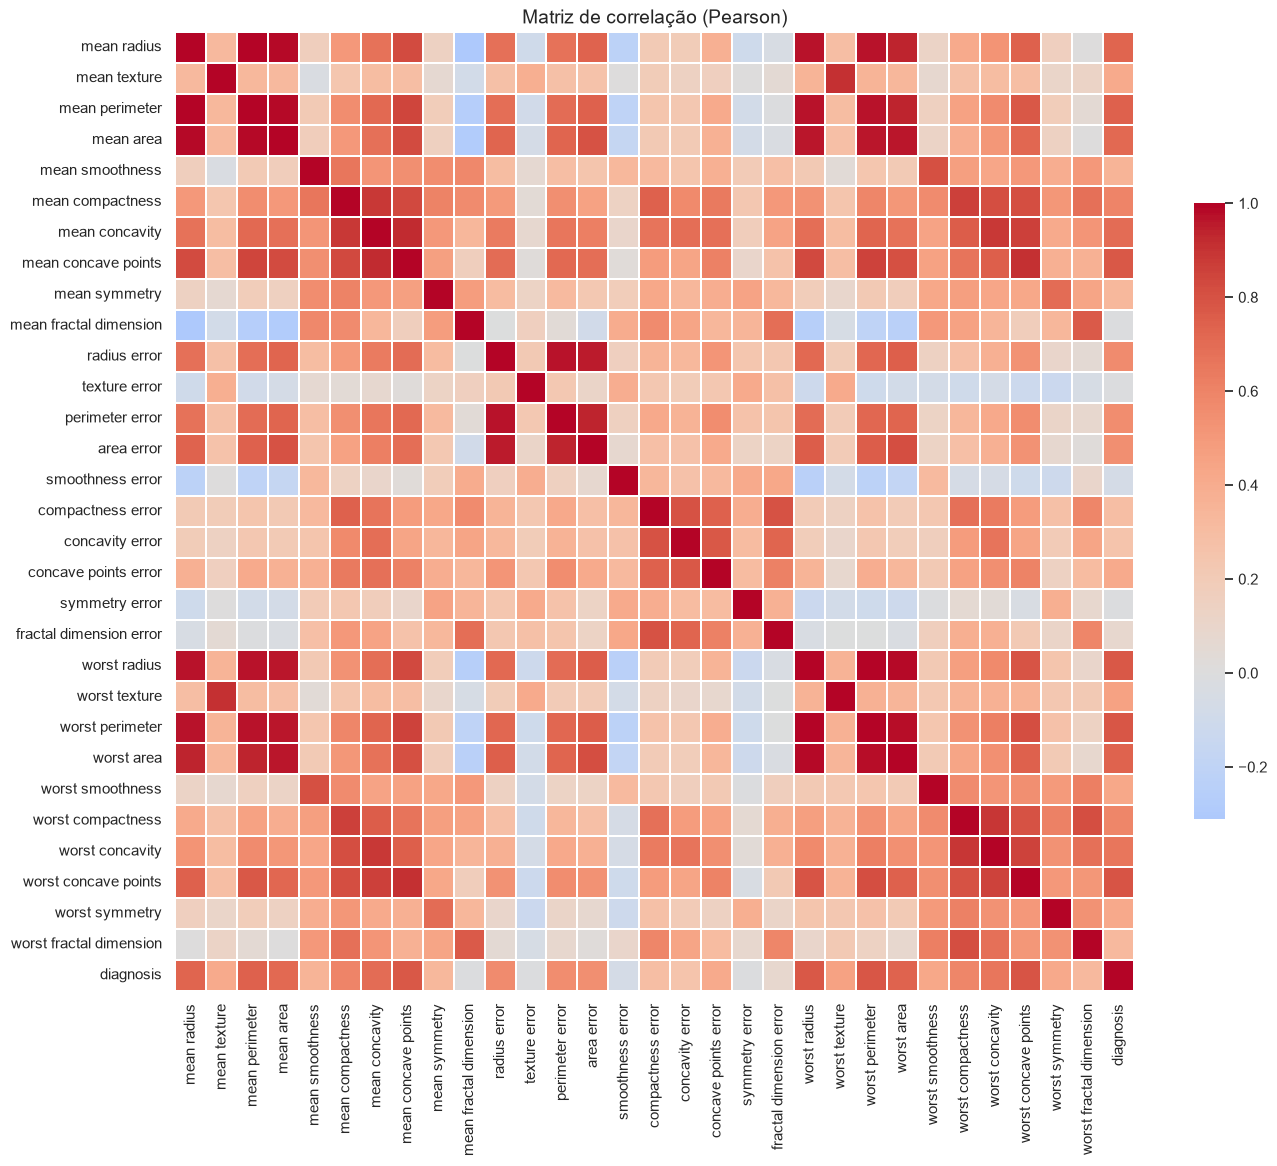

In [8]:
eda.plot_correlation_heatmap(df)
plt.show()


In [9]:
print("Features mais correlacionadas com o diagnóstico:\n")
print(top_corr.round(3).to_string())


Features mais correlacionadas com o diagnóstico:

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660


In [10]:
pares = eda.highly_correlated_pairs(df, threshold=0.9)
print(f"Pares com |correlação| >= 0.9 (redundância): {len(pares)}\n")
print(pares.head(10).to_string(index=False))


Pares com |correlação| >= 0.9 (redundância): 21

      feature_a       feature_b  correlacao
    mean radius  mean perimeter       0.998
   worst radius worst perimeter       0.994
    mean radius       mean area       0.987
 mean perimeter       mean area       0.987
   worst radius      worst area       0.984
worst perimeter      worst area       0.978
   radius error perimeter error       0.973
    mean radius    worst radius       0.970
 mean perimeter worst perimeter       0.970
 mean perimeter    worst radius       0.969


**Leitura crítica:**
- As features de "tamanho" (`radius`, `perimeter`, `area`) são fortemente
  correlacionadas com o diagnóstico **e** entre si — o que é esperado, pois
  perímetro e área derivam do raio. Isso é multicolinearidade.
- Multicolinearidade **infla a variância dos coeficientes** da Regressão
  Logística (dificulta interpretar o efeito isolado de cada feature), mas
  **não prejudica o poder preditivo**. Modelos de árvore/ensemble são robustos
  a isso.
- Para este projeto mantemos todas as features (o desempenho é o foco), mas
  registramos a redundância — em um cenário de produção poderíamos reduzir
  dimensionalidade (PCA) ou selecionar features para ganhar interpretabilidade.

## 4. Pré-processamento e separação treino/teste

### Decisões de projeto que garantem um resultado honesto

1. **Split estratificado** (80/20): preserva a proporção de malignos em treino
   e teste.
2. **Padronização dentro do pipeline**: o `StandardScaler` é encapsulado num
   `Pipeline` do scikit-learn. Ele aprende média e desvio **apenas do treino**
   a cada ajuste — nunca do teste. É isso que evita o **vazamento de dados
   (data leakage)** e mantém a estimativa de desempenho confiável. Essa
   invariante é verificada por um teste automatizado em `tests/`.

In [11]:
x, y = data_loader.split_features_target(df)
x_train, x_test, y_train, y_test = split_data(x, y)

print(f"Treino: {len(x_train)} amostras | Teste: {len(x_test)} amostras")
print(f"Proporção de maligno -> treino: {y_train.mean():.3f} | teste: {y_test.mean():.3f}")


Treino: 455 amostras | Teste: 114 amostras
Proporção de maligno -> treino: 0.374 | teste: 0.368


## 5. Modelagem

Treinamos **quatro** técnicas de famílias diferentes (o desafio pede duas ou
mais) para poder compará-las:

| Modelo | Família | Por que incluir |
|---|---|---|
| Regressão Logística | Linear | Baseline forte e interpretável |
| Árvore de Decisão | Regras | Não-linear, explicável por regras |
| KNN | Distância | Sensível à escala (testa a padronização) |
| Random Forest | Ensemble | Costuma ser o mais preciso; dá importância de features |

Cada modelo é um `Pipeline` (pré-processador + classificador), e usamos
`class_weight='balanced'` onde disponível para compensar o desbalanceamento.

### 5.1 Validação cruzada estratificada (só no treino)

Avaliamos com validação cruzada de 5 folds **antes** de tocar no teste, para
escolher e comparar modelos sem contaminar o holdout.

In [12]:
models = modeling.build_models(features)
cv_results = modeling.cross_validate_models(models, x_train, y_train)
cv_results.round(4)


,accuracy_media,accuracy_desvio,precision_media,precision_desvio,recall_media,recall_desvio,f1_media,f1_desvio,roc_auc_media,roc_auc_desvio
modelo,,,,,,,,,,
Regressão Logística,0.9714,0.0179,0.9650,0.0286,0.9588,0.0300,0.9616,0.0241,0.9954,0.0048
Random Forest,0.9626,0.0149,0.9477,0.0210,0.9529,0.0300,0.9500,0.0201,0.9896,0.0057
Árvore de Decisão,0.9319,0.0189,0.8937,0.0295,0.9294,0.0440,0.9104,0.0253,0.9284,0.0298
KNN,0.9692,0.0082,0.9879,0.0149,0.9294,0.0235,0.9575,0.0116,0.9860,0.0142


A Regressão Logística e o Random Forest lideram, com recall médio acima de
0.95 e ROC-AUC ~0.99 já na validação cruzada. Agora ajustamos todos os modelos
no treino completo e partimos para o teste.

In [13]:
models = modeling.fit_models(models, x_train, y_train)
print("Modelos treinados:", list(models.keys()))


Modelos treinados: ['Regressão Logística', 'Árvore de Decisão', 'KNN', 'Random Forest']


## 6. Avaliação no conjunto de teste

### 6.1 Por que RECALL é a métrica prioritária aqui

A escolha da métrica **depende do custo do erro**, não de uma regra genérica:

- **Falso negativo** = classificar um tumor **maligno** como benigno. A
  paciente é dispensada, o tratamento atrasa, o câncer avança. **Custo:
  altíssimo, potencialmente fatal.**
- **Falso positivo** = classificar um tumor **benigno** como maligno. Gera
  exames adicionais (biópsia) e ansiedade. **Custo: real, mas muito menor.**

Como os erros são assimétricos, priorizamos o **recall da classe maligna**
(minimizar falsos negativos), usando **F1** e **precision** como contrapeso
para não gerar alarmes em excesso. **Accuracy sozinha é enganosa** numa base
desbalanceada — um modelo que chutasse "benigno" sempre acertaria 63%.

In [14]:
test_results = evaluation.evaluate_all(models, x_test, y_test)
test_results.round(4)


,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.9737,0.9756,0.9524,0.9639,0.9954
Random Forest,0.9737,1.0000,0.9286,0.9630,0.9980
KNN,0.9561,0.9744,0.9048,0.9383,0.9825
Árvore de Decisão,0.9298,0.9250,0.8810,0.9024,0.9010


### 6.2 Matriz de confusão e curvas ROC

Melhor modelo por recall (maligno): Regressão Logística

  verdadeiro_negativo: 71
  falso_positivo: 1
  falso_negativo: 2
  verdadeiro_positivo: 40

  -> 2 falso(s) negativo(s): tumores malignos que passariam despercebidos (o erro mais grave).


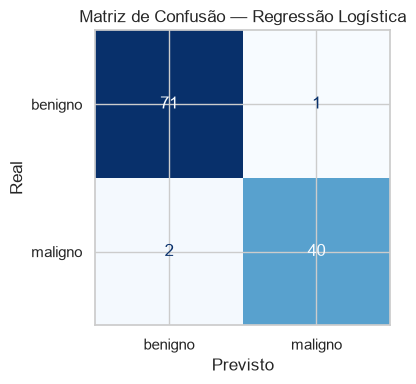

In [15]:
best_name = test_results.index[0]
best_model = models[best_name]
print(f"Melhor modelo por recall (maligno): {best_name}\n")

breakdown = evaluation.confusion_breakdown(best_model, x_test, y_test)
for k, v in breakdown.items():
    print(f"  {k}: {v}")
print(f"\n  -> {breakdown['falso_negativo']} falso(s) negativo(s): "
      "tumores malignos que passariam despercebidos (o erro mais grave).")

evaluation.plot_confusion_matrix(best_model, x_test, y_test, title=best_name)
plt.show()


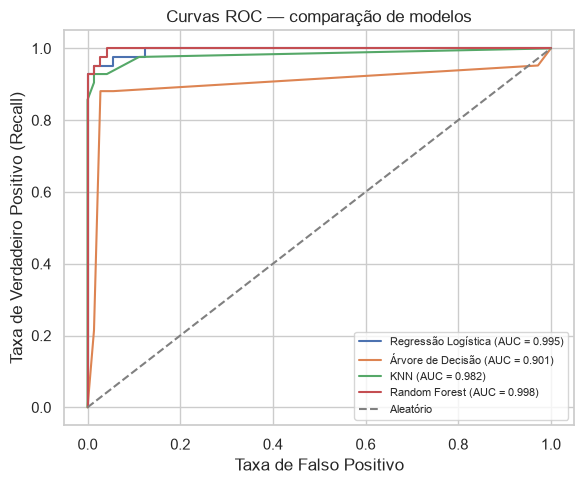

In [16]:
evaluation.plot_roc_curves(models, x_test, y_test)
plt.show()


**Interpretação dos resultados:**
- O melhor modelo atinge **recall ~0.95 para malignos** com apenas **1–2
  falsos negativos** em 114 pacientes de teste, mantendo alta precisão.
- As curvas ROC ficam praticamente coladas no canto superior esquerdo
  (AUC ~0.99), confirmando excelente capacidade de separação.
- O Random Forest chega a precision 1.0 (nenhum falso positivo), mas com recall
  um pouco menor. A escolha entre eles é um **trade-off clínico**: para triagem
  inicial, favorecemos recall (não deixar passar maligno).

## 7. Explicabilidade

Em saúde, um modelo "caixa-preta" não basta: o médico precisa **entender** por
que o sistema fez uma recomendação. Usamos duas técnicas complementares.

### 7.1 Importância de features

Top 10 features — Regressão Logística:

            feature  abs_coeficiente
      worst texture         1.466159
       radius error         1.309001
     worst symmetry         1.076920
mean concave points         0.969977
  compactness error         0.960795
    worst concavity         0.936887
         area error         0.935332
         worst area         0.905379
       worst radius         0.901723
    perimeter error         0.772293


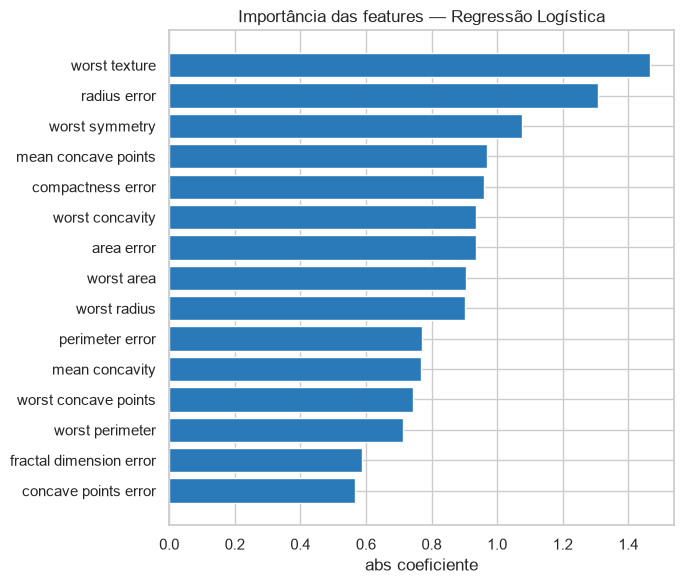

In [17]:
fi = explainability.feature_importance(best_model, features)
print(f"Top 10 features — {best_name}:\n")
print(fi.head(10).to_string(index=False))
explainability.plot_feature_importance(best_model, features, title=best_name)
plt.show()


### 7.2 SHAP — contribuição de cada feature por paciente

O **SHAP** (baseado em teoria dos jogos) atribui a cada feature o quanto ela
empurra a previsão para "maligno" ou "benigno", tanto no agregado quanto para
um **paciente individual**. Cada ponto é uma paciente; a cor é o valor da
feature (vermelho = alto). Pontos à direita empurram para *maligno*.

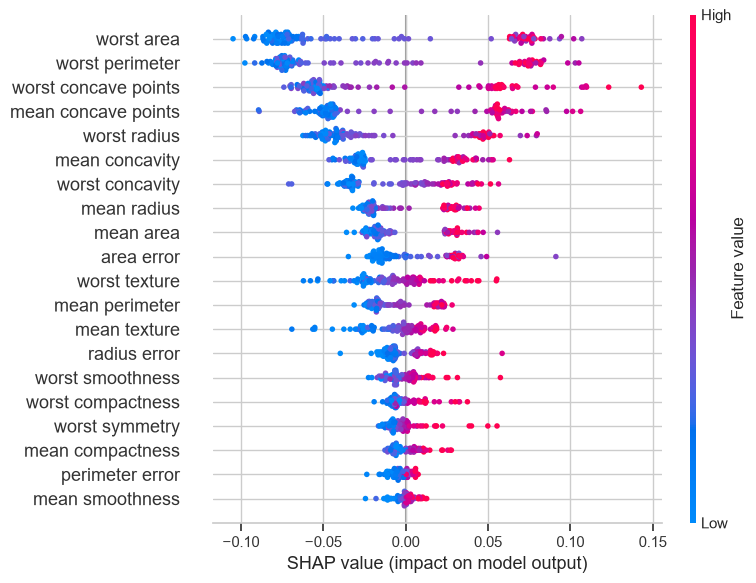

In [18]:
explainability.plot_shap_summary(models["Random Forest"], x_train, x_test, features)
plt.show()


**Leitura:** valores altos (vermelho) de `worst concave points`,
`worst perimeter`, `worst area` e `worst radius` empurram fortemente a previsão
para *maligno* — coerente com o conhecimento médico de que tumores malignos
têm núcleos maiores e contornos mais irregulares. O modelo aprendeu padrões
**clinicamente plausíveis**, o que aumenta a confiança nele.

## 8. Discussão crítica — o modelo pode ser usado na prática?

### O que os resultados mostram
- Desempenho muito alto e estável (recall ~0.95, F1 ~0.96, ROC-AUC ~0.99),
  validado por validação cruzada + holdout, **sem vazamento de dados**.
- As explicações (feature importance + SHAP) são clinicamente coerentes.

### Como poderia ser usado — e como NÃO deve ser
**Uso adequado: ferramenta de _apoio_ à triagem, nunca de decisão autônoma.**
- **Priorização de fila:** sinalizar casos de alto risco para revisão médica
  mais rápida.
- **Segunda opinião / rede de segurança:** alertar quando a avaliação humana e
  o modelo divergem, reduzindo a chance de um caso maligno passar batido.
- **O médico tem sempre a palavra final.** O modelo entrega uma probabilidade e
  uma explicação; o diagnóstico e a conduta são responsabilidade do
  profissional. Em triagem, faz sentido operar com um limiar que favoreça o
  recall (errar para o lado seguro) e encaminhar os positivos para confirmação.

### Limitações honestas
- **Base pequena e de uma fonte** (569 casos, Wisconsin). Não representa toda a
  diversidade de populações, equipamentos e laboratórios — é preciso validar em
  dados externos antes de qualquer uso real.
- As features vêm de **medições já extraídas** por especialistas a partir da
  PAAF; o modelo não substitui essa etapa nem o exame de imagem.
- **Não é dispositivo médico certificado.** Uso clínico real exigiria validação
  prospectiva, aprovação regulatória (ex.: ANVISA), monitoramento de viés entre
  subgrupos e governança de dados.
- Correlação não é causalidade: o modelo captura padrões estatísticos, não
  mecanismos biológicos.

### Conclusão
O projeto entrega uma **base sólida e reprodutível** de Machine Learning para
apoio ao diagnóstico em saúde da mulher, com pré-processamento sem vazamento,
comparação de modelos, métrica escolhida a partir do **custo clínico do erro**
e explicabilidade. É um **copiloto** para o profissional de saúde — acelera a
triagem e funciona como rede de segurança — mas a decisão final é, e deve
continuar sendo, humana.

---

### Próximos passos (Fase seguinte / EXTRA)
- **Visão computacional:** classificar mamografias/ultrassons diretamente com
  uma **CNN**. A estrutura do projeto (módulos + pipeline) já está pronta para
  receber esse segundo modelo.
- Validação em dataset externo e calibração de probabilidades.
- Ajuste de limiar de decisão orientado ao custo clínico (favorecendo recall).
